# 02. Khám phá phân phối và quan hệ trong dữ liệu

Notebook này tập trung vào mất cân bằng của `credit_risk`, độ lệch của `fraud_risk_score`, mối liên hệ giữa các feature và target, cùng phân tích phân khúc `employment_status` × nhóm thu nhập. Tên target và đường dẫn dữ liệu được đọc từ `configs/config.yaml`; không làm sạch hay biến đổi dữ liệu gốc.

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", palette="muted")

working_directory = Path.cwd().resolve()
project_root = next(
    (path for path in (working_directory, *working_directory.parents)
     if (path / "configs" / "config.yaml").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Không tìm thấy configs/config.yaml từ thư mục làm việc hiện tại.")

config_path = project_root / "configs" / "config.yaml"
with config_path.open(encoding="utf-8") as config_file:
    config = yaml.safe_load(config_file)

data_path = project_root / config["data"]["raw_path"]
if not data_path.is_file():
    raise FileNotFoundError(f"Không tìm thấy dữ liệu theo config: {data_path}")

figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

def save_figure(fig, filename):
    output_path = figures_dir / filename
    fig.savefig(output_path, dpi=160, bbox_inches="tight")
    print(f"Đã lưu biểu đồ: {output_path.relative_to(project_root)}")

classification_target = config["targets"]["classification"]
regression_target = config["targets"]["regression"]
df = pd.read_csv(data_path)

required_columns = {"income", "employment_status", classification_target, regression_target}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Thiếu các cột cần cho EDA: {sorted(missing_columns)}")

print(f"Dữ liệu: {data_path}")
print(f"Kích thước: {df.shape[0]:,} dòng x {df.shape[1]} cột")
print(f"Target phân loại: {classification_target}; target liên tục: {regression_target}")
display(df.head())

Dữ liệu: E:\Personal Project\Data science_analyze finance\data\raw\synthetic_finance_20250901.csv
Kích thước: 750,000 dòng x 23 cột
Target phân loại: credit_risk; target liên tục: fraud_risk_score


,customer_id,age,income,credit_score,employment_years,employment_status,education_level,marital_status,home_ownership,region,account_age_months,monthly_spending,credit_utilization,num_credit_cards,num_loans,late_payment_months,debt_to_income,savings_rate,investment_value,account_creation_date,last_transaction_date,credit_risk,fraud_risk_score
0,FN0000001,61,"33,027.3200",748,3.1000,Self-employed,Some College,Single,Mortgage,West,33,80.0000,0.3880,2,2,1,0.0300,0.3690,"7,404.5500",2023-04-07,2024-12-12,0,0.6100
1,FN0000002,39,"42,965.7100",661,4.4000,Self-employed,Some College,Single,Mortgage,West,32,674.9000,0.4350,2,1,4,0.1880,0.2810,"9,356.3000",2022-04-30,2024-12-21,0,0.3860
2,FN0000003,53,"22,000.0000",547,82.0000,Part-time,High School,Single,Rent,Northeast,14,976.7000,0.2950,2,3,2,0.5330,0.2320,"7,525.1900",2022-11-18,2024-12-18,2,0.4460
3,FN0000004,37,"43,531.0600",727,3.6000,Self-employed,Some College,Single,Mortgage,Midwest,11,80.0000,0.2610,1,0,1,0.0300,0.2570,"20,811.1000",2021-05-27,2024-12-26,0,0.4240
4,FN0000005,41,"22,956.1600",636,3.7000,Part-time,Some College,Married,Rent,Southeast,11,555.6900,0.4840,3,0,3,0.2900,0.2480,"2,863.8300",2024-02-15,2024-12-19,1,0.4430


## 1. Mất cân bằng lớp `credit_risk`

So sánh số lượng/tỷ lệ từng lớp, tỷ lệ lớp lớn nhất so với lớp nhỏ nhất và độ chính xác của baseline luôn dự đoán lớp phổ biến nhất. Baseline chỉ là mốc tham chiếu, không phải mô hình.

,count,percent
credit_risk,,
0,380490,50.73%
1,174426,23.26%
2,134274,17.90%
3,60810,8.11%


Lớp phổ biến nhất: 0
Lớp ít nhất: 3
Tỷ lệ lớp lớn nhất / lớp nhỏ nhất: 6.26:1
Accuracy baseline dự đoán lớp phổ biến nhất: 50.73%
Đã lưu biểu đồ: reports\figures\02_eda_credit_risk_imbalance.png


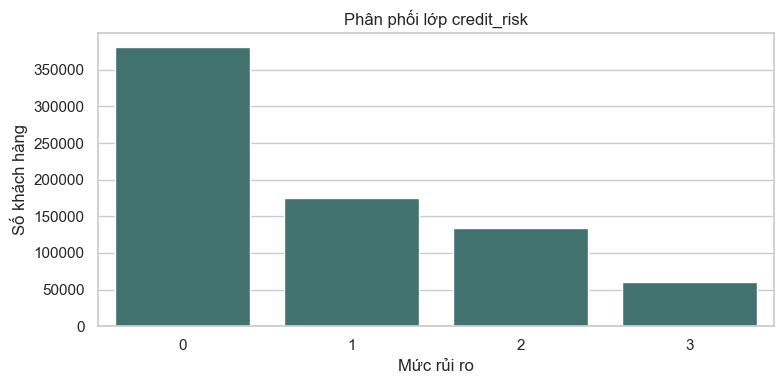

In [4]:
credit_risk = df[classification_target].dropna()
class_counts = credit_risk.value_counts().sort_index()
class_summary = pd.DataFrame({
    "count": class_counts,
    "percent": class_counts.div(class_counts.sum()).mul(100),
})
majority_class = class_counts.idxmax()
minority_class = class_counts.idxmin()
majority_baseline = class_counts.max() / class_counts.sum()
imbalance_ratio = class_counts.max() / class_counts.min()

display(class_summary.style.format({"percent": "{:.2f}%"}))
print(f"Lớp phổ biến nhất: {majority_class}")
print(f"Lớp ít nhất: {minority_class}")
print(f"Tỷ lệ lớp lớn nhất / lớp nhỏ nhất: {imbalance_ratio:.2f}:1")
print(f"Accuracy baseline dự đoán lớp phổ biến nhất: {majority_baseline:.2%}")

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=class_summary.index.astype(str), y=class_summary["count"], ax=ax, color="#397a73")
ax.set(title="Phân phối lớp credit_risk", xlabel="Mức rủi ro", ylabel="Số khách hàng")
plt.tight_layout()
save_figure(fig, "02_eda_credit_risk_imbalance.png")
plt.show()

## 2. Độ lệch của `fraud_risk_score`

Đo skewness, so sánh mean với median và các quantile. Thống kê tỷ lệ nằm ngoài khoảng `[0, 1]` chỉ là kiểm tra bổ sung nếu score được định nghĩa như xác suất; từ điển dữ liệu hiện không quy định miền giá trị này. Histogram tập trung đến P99 để biểu diễn rõ phần phân phối chính, nhưng thống kê vẫn dùng toàn bộ giá trị.

,value
count,"750,000.0000"
mean,0.4753
std,0.1595
min,0.1160
1%,0.2250
25%,0.3620
50%,0.4470
75%,0.5560
95%,0.7740
99%,0.9810


Skewness: 1.2578
Mean: 0.4753; median: 0.4470
Đã lưu biểu đồ: reports\figures\02_eda_fraud_score_skewness.png


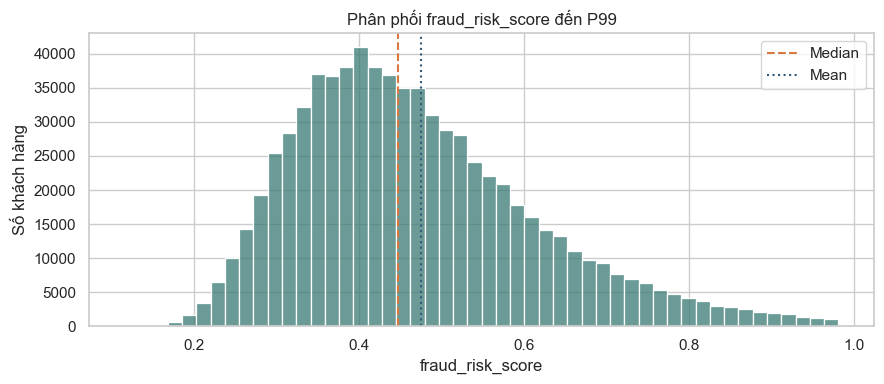

In [5]:
fraud_score = df[regression_target].dropna()
fraud_summary = fraud_score.describe(percentiles=[0.01, 0.25, 0.50, 0.75, 0.95, 0.99]).to_frame("value")
fraud_skewness = fraud_score.skew()
outside_unit_interval = fraud_score.lt(0) | fraud_score.gt(1)

fraud_summary.loc["skewness"] = fraud_skewness
fraud_summary.loc["outside_0_1_count"] = int(outside_unit_interval.sum())
fraud_summary.loc["outside_0_1_percent"] = outside_unit_interval.mean() * 100
display(fraud_summary)
print(f"Skewness: {fraud_skewness:.4f}")
print(f"Mean: {fraud_score.mean():.4f}; median: {fraud_score.median():.4f}")

p99 = fraud_score.quantile(0.99)
visible_scores = fraud_score[fraud_score <= p99]
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(visible_scores, bins=50, ax=ax, color="#397a73")
ax.axvline(fraud_score.median(), color="#d97941", linestyle="--", label="Median")
ax.axvline(fraud_score.mean(), color="#315a78", linestyle=":", label="Mean")
ax.set(
    title=f"Phân phối {regression_target} đến P99",
    xlabel=regression_target,
    ylabel="Số khách hàng",
)
ax.legend()
plt.tight_layout()
save_figure(fig, "02_eda_fraud_score_skewness.png")
plt.show()

## 3. Quan hệ giữa feature số và target

Dùng tương quan Spearman để đo quan hệ đơn điệu giữa feature số với `credit_risk` (xem như nhãn có thứ tự) và `fraud_risk_score`. Đây là phân tích liên hệ, không chứng minh quan hệ nhân quả; cần kiểm tra chất lượng dữ liệu trước khi diễn giải nghiệp vụ.

,credit_risk,fraud_risk_score
credit_score,-0.7096,-0.5339
credit_utilization,0.5728,0.6399
savings_rate,-0.5671,-0.4516
investment_value,-0.5470,-0.4112
income,-0.5078,-0.3689
late_payment_months,0.3884,0.4203
debt_to_income,0.3784,0.2232
employment_years,-0.2973,-0.1947
account_age_months,-0.2838,-0.2598
age,-0.2599,-0.2169


Đã lưu biểu đồ: reports\figures\02_eda_numeric_feature_target_spearman.png


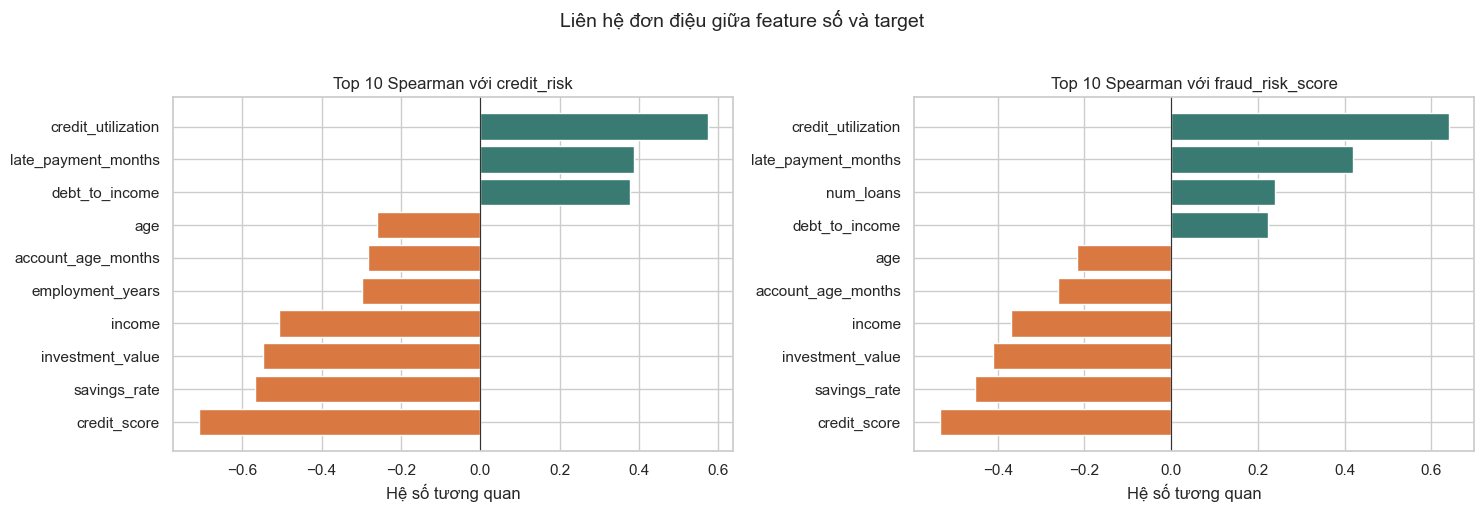

In [6]:
target_columns = [classification_target, regression_target]
numeric_features = [
    column for column in df.select_dtypes(include=np.number).columns
    if column not in target_columns
]

numeric_target_correlations = (
    df[numeric_features + target_columns]
    .corr(method="spearman")[target_columns]
    .loc[numeric_features]
)
display(numeric_target_correlations.reindex(
    numeric_target_correlations.abs().max(axis=1).sort_values(ascending=False).index
))

fig, axes = plt.subplots(1, 2, figsize=(15, max(5, len(numeric_features) * 0.35)), sharey=False)
for ax, target in zip(axes, target_columns):
    top_features = numeric_target_correlations[target].abs().nlargest(10).index
    values = numeric_target_correlations.loc[top_features, target].sort_values()
    bar_colors = ["#397a73" if value >= 0 else "#d97941" for value in values]
    ax.barh(values.index, values.values, color=bar_colors)
    ax.axvline(0, color="#333333", linewidth=0.8)
    ax.set(title=f"Top 10 Spearman với {target}", xlabel="Hệ số tương quan", ylabel="")

fig.suptitle("Liên hệ đơn điệu giữa feature số và target", y=1.02, fontsize=14)
plt.tight_layout()
save_figure(fig, "02_eda_numeric_feature_target_spearman.png")
plt.show()

## 4. Quan hệ giữa feature phân loại và target

So sánh trung bình `credit_risk` (nhãn thứ bậc) và mean/median `fraud_risk_score` theo từng nhóm categorical. Bảng luôn kèm số lượng quan sát để tránh diễn giải nhóm quá nhỏ như một xu hướng ổn định.

In [7]:
categorical_features = [
    column for column in [
        "employment_status", "education_level", "marital_status",
        "home_ownership", "region",
    ]
    if column in df.columns
]

categorical_target_tables = []
for feature in categorical_features:
    grouped_summary = (
        df.groupby(feature, dropna=False, observed=True)
        .agg(
            n=(classification_target, "size"),
            mean_credit_risk=(classification_target, "mean"),
            mean_fraud_score=(regression_target, "mean"),
            median_fraud_score=(regression_target, "median"),
        )
        .reset_index()
    )
    grouped_summary["feature"] = feature
    grouped_summary["group"] = grouped_summary[feature].astype("string").fillna("(Thiếu)")
    categorical_target_tables.append(
        grouped_summary[["feature", "group", "n", "mean_credit_risk", "mean_fraud_score", "median_fraud_score"]]
    )

categorical_target_summary = pd.concat(categorical_target_tables, ignore_index=True)
display(
    categorical_target_summary.sort_values(
        ["feature", "mean_credit_risk"], ascending=[True, False]
    ).reset_index(drop=True)
)

,feature,group,n,mean_credit_risk,mean_fraud_score,median_fraud_score
0,education_level,High School,188447,1.6736,0.5718,0.5420
1,education_level,Some College,215714,0.8951,0.4864,0.4640
2,education_level,Bachelor,179880,0.4844,0.4398,0.4210
3,education_level,Master,98939,0.2418,0.4046,0.3880
4,education_level,PhD,67020,0.0878,0.3678,0.3530
5,employment_status,Unemployed,93838,2.0084,0.6067,0.5760
6,employment_status,Part-time,142972,1.2700,0.5278,0.5020
7,employment_status,Self-employed,223553,0.7698,0.4731,0.4510
8,employment_status,Full-time,163258,0.3983,0.4286,0.4100
9,employment_status,Retired,126379,0.1445,0.3824,0.3660


## 5. Phân khúc `employment_status` × nhóm thu nhập

Chia `income` thành 4 nhóm theo tứ phân vị trên toàn bộ dữ liệu, sau đó so sánh quy mô, điểm `credit_risk` trung bình, tỷ lệ rủi ro cao (lớp 3) và `fraud_risk_score` theo từng tổ hợp. Thu nhập thiếu được giữ thành một nhóm riêng để không bị âm thầm loại khỏi bảng.

,income_group,income_lower_bound,income_upper_bound
0,Q1,"22,000.0000","24,860.9300"
1,Q2,"24,860.9300","36,301.5850"
2,Q3,"36,301.5850","53,092.8525"
3,Q4,"53,092.8525","4,977,921.3658"


,employment_status,income_group,customer_count,mean_credit_risk,high_credit_risk_percent,mean_fraud_score,median_fraud_score
0,Full-time,Q1,13570,0.7449,3.3898,0.4634,0.4420
1,Full-time,Q2,36649,0.5543,1.6890,0.4442,0.4250
2,Full-time,Q3,55033,0.3899,0.7432,0.4294,0.4110
3,Full-time,Q4,58006,0.2265,0.2845,0.4098,0.3940
4,Part-time,Q1,59344,1.5127,17.1087,0.5523,0.5260
5,Part-time,Q2,47156,1.2307,9.7040,0.5219,0.4970
6,Part-time,Q3,27523,0.9891,6.0713,0.5013,0.4790
7,Part-time,Q4,8949,0.7309,3.1400,0.4777,0.4550
8,Retired,Q1,2677,0.4886,1.9425,0.4304,0.4140
9,Retired,Q2,11979,0.3266,0.6428,0.4118,0.3940


Đã lưu biểu đồ: reports\figures\02_eda_employment_income_segments.png


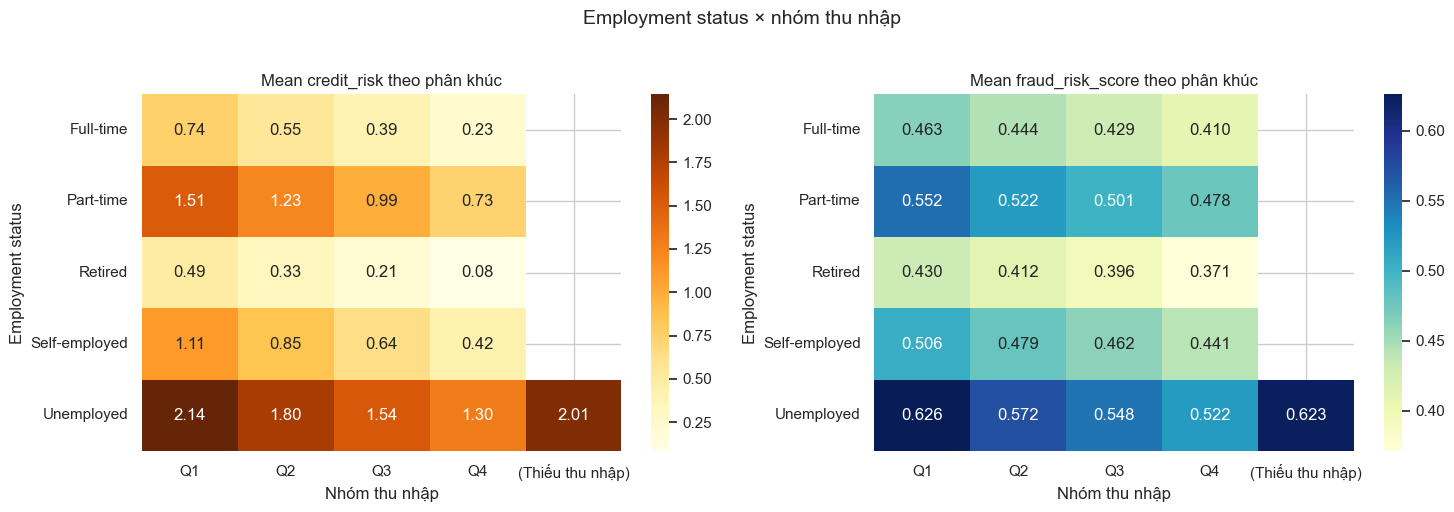

In [8]:
segment_data = df[[
    "employment_status", "income", classification_target, regression_target,
]].copy()
segment_data["employment_status"] = segment_data["employment_status"].fillna("(Thiếu employment_status)")
income_quartiles, income_cut_points = pd.qcut(
    segment_data["income"], q=4, retbins=True, duplicates="drop"
)
quartile_labels = [f"Q{index + 1}" for index in range(len(income_cut_points) - 1)]
income_quartiles = income_quartiles.cat.rename_categories(quartile_labels)
segment_data["income_group"] = income_quartiles.astype("object").fillna("(Thiếu thu nhập)")
income_group_order = quartile_labels + ["(Thiếu thu nhập)"]
segment_data["income_group"] = pd.Categorical(
    segment_data["income_group"], categories=income_group_order, ordered=True
)

display(pd.DataFrame({
    "income_group": quartile_labels,
    "income_lower_bound": income_cut_points[:-1],
    "income_upper_bound": income_cut_points[1:],
}))

segment_summary = (
    segment_data.groupby(["employment_status", "income_group"], observed=True, dropna=False)
    .agg(
        customer_count=(regression_target, "size"),
        mean_credit_risk=(classification_target, "mean"),
        high_credit_risk_percent=(classification_target, lambda values: values.eq(3).mean() * 100),
        mean_fraud_score=(regression_target, "mean"),
        median_fraud_score=(regression_target, "median"),
    )
    .reset_index()
)
display(segment_summary.sort_values(["employment_status", "income_group"]).reset_index(drop=True))

credit_risk_pivot = segment_summary.pivot(
    index="employment_status", columns="income_group", values="mean_credit_risk"
)
fraud_score_pivot = segment_summary.pivot(
    index="employment_status", columns="income_group", values="mean_fraud_score"
)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(credit_risk_pivot, annot=True, fmt=".2f", cmap="YlOrBr", ax=axes[0])
axes[0].set(title="Mean credit_risk theo phân khúc", xlabel="Nhóm thu nhập", ylabel="Employment status")
sns.heatmap(fraud_score_pivot, annot=True, fmt=".3f", cmap="YlGnBu", ax=axes[1])
axes[1].set(title="Mean fraud_risk_score theo phân khúc", xlabel="Nhóm thu nhập", ylabel="Employment status")
fig.suptitle("Employment status × nhóm thu nhập", y=1.02, fontsize=14)
plt.tight_layout()
save_figure(fig, "02_eda_employment_income_segments.png")
plt.show()